# RAG-Anything: From Documents to Evidence-Grounded Answers

This lesson follows one question:

> How many books can a student borrow at a time, for how long, and how can they renew them?

Open the [two-page Library Borrowing Guide](../data/library-guide.pdf) and find the answer yourself. Then watch the program do the same job: **organize the material for retrieval, find the evidence, and ask a model to compose an answer.**

Follow the borrowing table and renewal rule throughout the lesson; use the diagram to check the action sequence. You do not need to memorize every field or API name.

| Evidence to follow | Location in the PDF | Part of the question it answers |
| --- | --- | --- |
| **Table evidence:** 3 books, 14 days | Page 1 | How many books? For how long? |
| **Text evidence:** renew once for 7 extra days if nobody else has reserved the book | Page 2 | How does renewal work? What are the conditions? |
| **Image evidence:** check the due date → find the book → renew and check the new date | Page 2 | In what order should the actions happen? |

## The two-part processing map

```mermaid
flowchart TD
    subgraph INDEX["Part I: Build the index"]
        PDF["Two-page library PDF"] --> PARSE["Docling parses text, a table, and an image"]
        PARSE --> CHUNKS["Split text; describe the table and image"]
        CHUNKS --> TEXT["Store chunk content and provenance"]
        CHUNKS --> VECTOR["Generate chunk embeddings"]
        CHUNKS --> GRAPH["Extract entities and relationships; build graph and vector indexes"]
    end
    subgraph QUERY["Part II: Retrieve and answer"]
        Q["How many books, for how long, and how to renew?"] --> SEARCH["mix: vector and graph retrieval"]
        SEARCH --> EVIDENCE["Retrieve relevant chunks and combine evidence"]
        EVIDENCE --> PROMPT["Instructions + evidence + original question"]
        PROMPT --> ANSWER["Answer: 3 books, 14 days, renewal steps and conditions"]
        ANSWER --> REF["Include source references"]
    end
    VECTOR --> SEARCH
    GRAPH --> SEARCH
    TEXT --> EVIDENCE
```

**Ingestion can finish before any question arrives.** Parsing a PDF and building an index do not train or change the answer model. We will add caching to this main path in section 9.

By the end, you should be able to explain three things without reading the code:

1. How do “3 books” and “14 days” travel from the PDF table into the answer?
2. What do vectors and the knowledge graph each help the system find?
3. Which model call is avoided when a repeated question hits the cache?

This is a reorganized edition of [the original notebook](rag_anything_walkthrough.ipynb), which remains unchanged. Saved outputs have been carried into the grouped cells from the preceding notebook version. They are historical observations, not a new execution of these grouped cells. Model descriptions, graph contents, IDs, and retrieval results can change on a fresh run. Use new outputs as the source of truth.

## Reading and execution guide

| Part | Steps | Processing question |
| --- | --- | --- |
| [Part I — Document ingestion](#part-1) | [1. Inputs](#step-1) · [2. Model roles](#step-2) · [3. Wiring](#step-3) · [4. Parsing](#step-4) · [5. Chunk construction](#step-5) · [6. Index construction](#step-6) | How does a source document become readable chunks, vectors, and a connected graph? |
| [Part II — Retrieval and answering](#part-2) | [7. Retrieve evidence](#step-7) · [8. Assemble model input](#step-8) · [9. Answer and reuse](#step-9) | How does a question select evidence and become an answer? |
| [10. Summary and coverage](#step-10) | Self-checks, coverage limits, and source map | What has this example demonstrated, and what remains outside its worked path? |

Run cells from top to bottom. Setup uses one cell and one printout. Each core operation now runs and prints its related outputs in one cell: parsing, ingestion, model-call inspection, stored chunks, graph inspection, retrieval, context, prompt, and answering. Change an item index and rerun that operation to inspect another record. Rerunning a cell that contains a query or ingestion call repeats that operation; reprinting an existing variable alone does not. Library messages appear normally; no log capture is needed. Restart the kernel when switching from the earlier edition so its old logging setup is not still active.

Q&A and self-checks appear at the end of their relevant section. Complete extraction examples remain expandable. See the [README](../README.md) for installation and startup. Ingestion and queries can call cloud models; reading saved outputs does not. The optional experiments retain their original `run_experiments = True` setting.

**Component boundary:** choose **Docling or MinerU** as the document parser. This run selects Docling; it does not run MinerU first and Docling second. RAGAnything routes the parsed content; **LightRAG performs the ordinary text chunking**. Table and image processors build their own textual representations. [Step 10](#coverage) distinguishes demonstrated behavior from additional branches.


<a id="part-1"></a>
# Part I — From source documents to chunks, vectors, and a graph

The index is built before answering. Steps 1–3 prepare the components; Steps 4–6 follow the material through parsing, chunk construction, and indexing. Diagrams describe data dependencies; independent storage and model tasks can overlap in execution.


<a id="step-1"></a>
## 1. Set up the document, models, and storage

This cell imports the required RAG components, reads `src/.env`, and sets three paths: the source PDF, parsed files, and saved index. Run it from the project folder or `src/`. Set the API key and model settings in `src/.env` first; the key is not printed.

Setup ends with one short printout. The detailed outputs start with document parsing in Step 4.


In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from lightrag import QueryParam
from lightrag.llm.openai import openai_complete_if_cache, openai_embed
from lightrag.utils import EmbeddingFunc
from raganything import RAGAnything, RAGAnythingConfig, set_prompt_language

# Start the notebook from the project folder or its src folder.
project_dir = Path.cwd()
if project_dir.name == "src":
    project_dir = project_dir.parent

pdf_path = project_dir / "data/library-guide.pdf"
parsed_dir = project_dir / "outputs/parsed"
storage_dir = project_dir / "outputs/library_rag_storage"

load_dotenv(project_dir / "src/.env")
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("OPENAI_BASE_URL")
llm_model = os.getenv("LLM_MODEL")
vision_model = os.getenv("VISION_MODEL")
embedding_model = os.getenv("EMBEDDING_MODEL")
embedding_dim = int(os.environ["EMBEDDING_DIM"])

print(f"""Source: {pdf_path.name}
Parsed files: {parsed_dir}
Index: {storage_dir}
Text model: {llm_model}
Vision model: {vision_model}
Embedding model: {embedding_model} ({embedding_dim} dimensions)""")


Source: library-guide.pdf
Parsed files: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed
Index: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
Text model: gpt-6-luna
Vision model: gpt-6-luna
Embedding model: text-embedding-3-small (1536 dimensions)


<a id="step-2"></a>
## 2. Assign interpretation, vision, and embedding to their models

**Question for this step: Who interprets content, and who turns text into numbers?** The next cell defines the three model callbacks. Defining them does not send a model request.

```mermaid
flowchart LR
    T["Text, table structure, or an extraction task"] --> L["llm: text model"] --> O["Analysis, entities, relationships, keywords, or an answer"]
    I["Image and related text"] --> V["vision: vision model"] --> D["Text description of the image"]
    S["A batch of texts"] --> E["embed: embedding model"] --> N["One numeric vector per text"]
```

`calls` is the current kernel's **model call log**. Each callback records its input and output so that we can inspect what happened. It is not the persistent cache; resetting this list does not clear cached results on disk.

**Remember these roles:** `llm` interprets and generates text; `vision` interprets images; `embed` encodes text. The text model extracts entities and relationships. Embedding alone does not build a graph or write a summary.

The callbacks use LightRAG’s OpenAI helpers. The plain Python list `calls` retains successful model inputs and outputs for the core examples below. Vision records keep the text and image count; Step 4 displays the image. Embedding records keep the vector shape and first six coordinates. `EmbeddingFunc` in Step 3 declares the model and dimensions, while `openai_embed.func` sends those dimensions to the API.


In [2]:
# Keep model inputs and outputs so we can read them during the core steps.
calls = []

async def llm(prompt, system_prompt=None, history_messages=None, **kwargs):
    output = await openai_complete_if_cache(
        llm_model, prompt, system_prompt=system_prompt,
        history_messages=history_messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    calls.append({
        "kind": "llm", "prompt": prompt, "system_prompt": system_prompt,
        "history_messages": history_messages or [], "output": output,
    })
    return output

async def vision(prompt, system_prompt=None, image_data=None, messages=None, **kwargs):
    # Ingestion supplies a PNG; image-enhanced queries supply complete messages.
    if messages is None:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        content = [{"type": "text", "text": prompt}]
        if image_data:
            content.append({
                "type": "image_url",
                "image_url": {"url": f"data:image/png;base64,{image_data}"},
            })
        messages.append({"role": "user", "content": content})

    output = await openai_complete_if_cache(
        vision_model, "", messages=messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    image_count = sum(
        part["type"] == "image_url"
        for message in messages if isinstance(message["content"], list)
        for part in message["content"]
    )
    calls.append({
        "kind": "vision", "prompt": prompt, "system_prompt": system_prompt,
        "images": image_count, "output": output,
    })
    return output

async def embed(texts):
    vectors = await openai_embed.func(
        texts, model=embedding_model, base_url=base_url, api_key=api_key,
        embedding_dim=embedding_dim, max_token_size=8192,
    )
    calls.append({
        "kind": "embed", "texts": list(texts),
        "shape": vectors.shape, "sample": vectors[0, :6].tolist(),
    })
    return vectors


<a id="step-3"></a>
## 3. Connect the parser, model callbacks, and indexing engine

**Question for this step: Who connects the parser, models, and indexes?**

| Component | Role in this lesson |
| --- | --- |
| Docling | Recognizes text, a table, and an image in the PDF |
| RAGAnything | Coordinates multimodal processing and sends content through ingestion and querying |
| LightRAG | Splits text, manages vector and graph indexes, retrieves evidence, and coordinates answer generation |

This project uses LightRAG, which follows a graph-assisted retrieval approach. It does not separately invoke Microsoft's GraphRAG package.

**Before running, notice two settings:** `chunk_token_size=75` and `chunk_overlap_token_size=20`. They will determine how the ordinary text becomes overlapping chunks. A token is a unit used by a model's tokenizer; it is not necessarily a whole word or character.

The next cell creates `rag` and selects English prompts. It does not ingest the PDF yet. On your first pass, just confirm the `docling` parser, the three model callbacks, and the 75/20 chunking settings. We will inspect their effect in section 5.


In [3]:
set_prompt_language("en")

config = RAGAnythingConfig(
    parser="docling",
    parser_output_dir=str(parsed_dir),
    working_dir=str(storage_dir),
    display_content_stats=False,
)

rag = RAGAnything(
    config=config,
    llm_model_func=llm,
    vision_model_func=vision,
    embedding_func=EmbeddingFunc(
        embedding_dim=embedding_dim,
        max_token_size=8192,
        model_name=embedding_model,
        func=embed,
    ),
    lightrag_kwargs={
        "llm_model_name": llm_model,
        "chunk_token_size": 75,
        "chunk_overlap_token_size": 20,
        "addon_params": {"language": "English"},
    },
)


INFO: RAGAnything initialized with config:
INFO:   Working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
INFO:   Parser: docling
INFO:   Parse method: auto
INFO:   Multimodal processing - Image: True, Table: True, Equation: True
INFO:   Max concurrent files: 1


<a id="step-4"></a>
## 4. Parse the PDF into typed blocks and source locations

**Question for this step: What does the program receive for text, a table, and an image?**

```mermaid
flowchart LR
    PDF["Two-page PDF"] --> D["Local Docling parsing"]
    D --> ID["doc_id: document identifier"]
    D --> T["21 text blocks"]
    D --> TB["1 table block"]
    D --> I["1 image block"]
```

**Input → operation → output:** PDF → `parse_document` → `content_list` and `doc_id`.

**Predict before running:** “3 books” and “14 days” should appear in a table block. The renewal condition and “7 extra days” should appear in text on page 2. The next cell parses the material; it does not generate an answer or compute embeddings.

**In the parsing output, find two things:**

1. The type counts: `text: 21, table: 1, image: 1`.
2. The original text describing when a book can be renewed, and its `page_idx`.

The PDF has a text layer, so OCR is disabled. On its first run, Docling may still download local layout or table-recognition models. This example has no equations. In a document containing equations, any `equation` blocks recognized by the parser can enter the later multimodal processing stage.


**Parse the PDF and inspect its contents**

`rag.parse_document` returns `content_list` and `doc_id`. This cell shows the document ID, counts of text/table/image blocks, one block, and the extracted image with its metadata. Change `block_index` to inspect another block; index 14 selects the renewal condition in the saved example. `Image` renders the PNG; the other outputs use plain prints.


INFO: Starting document parsing: /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf
INFO: Using docling parser with method: auto
INFO: Detected PDF file, using parser for PDF...
/Users/weiningxu/Documents/Project/rag_anything_playground/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1118 18:07:42.632000 8236 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 12404.18it/s]
INFO: Parsing /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf complete! Extracted 23 content blocks



Document ID:


doc-501ac0a4b56d2d98331eb3d9164f0dfd



Parsed blocks by type:


text 21
table 1
image 1



Selected parsed block:


{'type': 'text', 'text': 'If nobody else has reserved it, renew once for 7 extra days.', 'page_idx': 1}



Image metadata:


{'type': 'image', 'img_path': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png', 'image_caption': ['Figure 1. Renewal steps'], 'image_footnote': [], 'page_idx': 1}


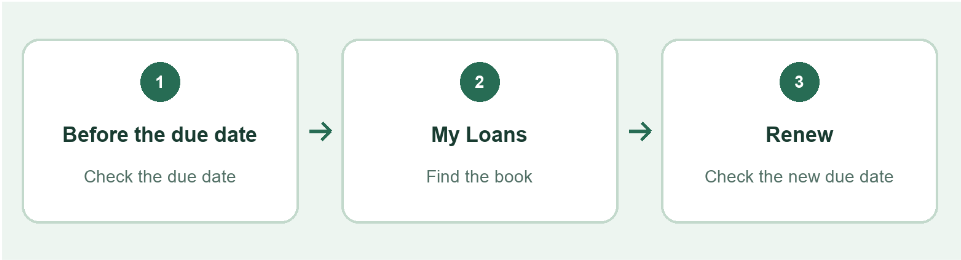

In [ ]:
content_list, doc_id = await rag.parse_document(str(pdf_path), allow_ocr=False)

print('\nDocument ID:')

print(doc_id)

print('\nParsed blocks by type:')

for block_type in ("text", "table", "image"):
    print(block_type, sum(block["type"] == block_type for block in content_list))

print('\nSelected parsed block:')

block_index = 14
print(content_list[block_index])

print('\nImage metadata:')

image_block = next((block for block in content_list if block["type"] == "image"), None)
print(image_block if image_block else "No image block was parsed.")

from IPython.display import Image

Image(filename=image_block["img_path"], width=520)


### 4.1 Read the parsed block schema

A parsed text block has this shape. The sentence below illustrates the renewal rule; inspect the output above for the exact parsed wording.

```json
{
  "type": "text",
  "text": "If nobody else has reserved the book, you may renew it once for 7 extra days.",
  "page_idx": 1
}
```

`page_idx=1` means page **2**, because page indices start at zero. A table block stores cell structure in `table_body`; an image block's `img_path` points to an extracted PNG.

The 21 text blocks also include headings, captions, and page numbers. The count does not mean there are 21 complete rules.


### 4.2 Q&A — Parsed blocks are not retrieval chunks

**Pause and predict — Check 1: Do we already have 23 chunks and 23 vectors?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

**Not yet.** We have 23 parsed blocks representing the PDF's content and layout. Ingestion will join and split the ordinary text, then process the table and image. This run ultimately produces 6 chunks.

If you answered “yes,” you are mixing up **parsed layout elements** and **retrieval units**. Follow the same evidence from section 4 into section 5.

</details>


<a id="step-5"></a>
## 5. Route the blocks and construct retrieval chunks

**Question for this step: How does parsed content become material we can search later?** `insert_content_list` looks like one call, but it coordinates all of the work below.

```mermaid
flowchart TD
    INPUT["23 parsed blocks"] --> T["21 text blocks"]
    INPUT --> TABLE["1 table"]
    INPUT --> IMAGE["1 image"]
    T --> JOIN["Join ordinary text: 180 tokens"]
    JOIN --> SPLIT["Window: 75 tokens; overlap: 20 tokens"]
    SPLIT --> FOUR["4 text chunks"]
    TABLE --> LLM["Text model analyzes table structure and nearby text"]
    LLM --> TC["Table chunk: 1941 tokens"]
    IMAGE --> VLM["Vision model describes the image"]
    VLM --> IC["Image chunk: 430 tokens"]
    FOUR --> STORE["Store 6 chunks and their provenance"]
    TC --> STORE
    IC --> STORE
```

The three branches produce textual retrieval units. Analysis and embedding are separate tasks; section 5.2 follows the multimodal branch.

### 5.1 Join and split ordinary text

**Understand the text windows.** The joined ordinary text contains 180 tokens in this run. A 75-token window with a 20-token overlap advances by 55 tokens each time.

| Text chunk | Token range | Length | Overlap with previous chunk |
| --- | --- | ---: | --- |
| 1 | 1–75 | 75 | None |
| 2 | 56–130 | 75 | 56–75 |
| 3 | 111–180 | 70 | 111–130 |
| 4 | 166–180 | 15 | 166–180 |

The final chunk has only 15 tokens and is entirely contained in the end of chunk 3. This last pair therefore shares 15 tokens; 20 is the configured overlap for full windows.

Overlap repeats text near a boundary in adjacent chunks, reducing the chance that a split loses important context. Compare the end of one text chunk with the beginning of the next. Token windows do not guarantee complete sentences, and a chunk can cross a page boundary.

**After running, check the status only:** `fully_processed` should be `True`; this saved run has `chunks_count=6`. A successful `insert_content_list` call returns `None`. The subsequent `status` record tells us whether processing finished.


### 5.2 Interpret the table and image with surrounding text

**Question:** How can a table or image become searchable text without losing its structure?

**Analysis:** Interpretation receives the original modality plus selected context. Graph extraction later receives the resulting textual representation.

| Material | What the earlier analysis receives | What graph extraction later receives |
| --- | --- | --- |
| Body text | No separate table/image analysis | One text chunk |
| Table | Structured table cells, captions or footnotes if present, and surrounding text | Table structure and metadata, plus the generated analysis |
| Image | Actual image pixels, caption if present, and surrounding text | A textual representation containing the visual description, image path, caption, and contextual information |

**Select nearby context before interpretation.** The default context setting includes text from the current page and one page on either side, subject to a 2,000-token limit. Our guide has only two short pages, so text from both pages can be included. The default context filter includes text, not the nearby table or image pixels themselves.

For example, the cells contain **3 books** and **14 days**; renewal information in the table analysis can come from nearby paragraphs. Inspect the original PDF before attributing that rule to the table itself. The text model interprets the table; the vision model interprets image pixels. Their descriptions become inputs to chunk storage, embedding, and graph extraction.


**Index the parsed material and read its status**

`rag.insert_content_list` builds or reuses the index. The positions in `calls` identify the model work performed during ingestion. After insertion, the cell reads `rag.get_document_processing_status` and prints completion, chunk count, and the full status record together.


In [ ]:
before_insert = len(calls)
await rag.insert_content_list(content_list, file_path=str(pdf_path), doc_id=doc_id)
after_insert = len(calls)

status = await rag.get_document_processing_status(doc_id)

print(f'\nFully processed: {status["fully_processed"]}')

print(f'\nStored chunk count: {status["chunks_count"]}')

print(f'\nProcessing progress: {status["processing_progress"]}%')

print('\nFull status record:')

print(status)


INFO: Parser 'docling' installation verified
INFO: Initializing LightRAG with parameters: {'working_dir': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage', 'llm_model_name': 'gpt-6-luna', 'chunk_token_size': 75, 'chunk_overlap_token_size': 20, 'addon_params': {'language': 'English'}}
INFO: [] Created new empty graph file: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/graph_chunk_entity_relation.graphml
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_entities.json'} 0 data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_relationships.json'} 0 data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Document

INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"



Fully processed:


True



Stored chunk count:


6



Full status record:


{'exists': True, 'text_processed': True, 'multimodal_processed': True, 'fully_processed': True, 'chunks_count': 6, 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9', 'chunk-f74d3981177947bc583a0860d03ffe3f', 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9', 'chunk-0bec09cbf50b78e30405fdc3229058fb', 'chunk-604374813fb8c7f3a8154e53d151ad0b', 'chunk-7f4f0a32cfcf638b9c46120a873924cb'], 'status': <DocStatus.PROCESSED: 'processed'>, 'updated_at': '2026-11-18T10:10:32+00:00', 'raw_status': {'status': <DocStatus.PROCESSED: 'processed'>, 'chunks_count': 6, 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9', 'chunk-f74d3981177947bc583a0860d03ffe3f', 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9', 'chunk-0bec09cbf50b78e30405fdc3229058fb', 'chunk-604374813fb8c7f3a8154e53d151ad0b', 'chunk-7f4f0a32cfcf638b9c46120a873924cb'], 'content_summary': 'Library Borrowing Guide\n\nBorrowing and returning books\n\nBefore borrowing, check that your account is eligible.\n\nThe table lists the limit and standard l

### 5.3 Inspect interpretation and encoding as separate operations

The following cells each inspect one complete model operation: table analysis, vision analysis, or embedding. Each groups its input and output together. **Compare these two kinds of result:**

- An image or table description is readable text, such as an explanation of the renewal diagram.
- An embedding result has an array shape and a numeric sample. For example, `(N, 1536)` means N vectors, each with 1536 dimensions.

In this example, the table chunk explains the 3-book limit and 14-day loan period. The image chunk describes the renewal steps. Descriptions may incorporate nearby text, so return to the PDF when checking a fact.

If this run reused an already processed document or cached results, there may be fewer new calls, or no sample for a particular task. An empty `calls` list alone does not show that ingestion failed; also inspect the completion status.


**Select the ingestion model calls and count them**

Select table, vision, and embedding samples from this ingestion, then print the number of each kind of call. Reusing an index or cached results can leave a sample as `None`.


In [ ]:
from raganything.prompt import PROMPTS

index_calls = calls[before_insert:after_insert]
table_sample = next((call for call in index_calls if call.get("system_prompt") == PROMPTS["TABLE_ANALYSIS_SYSTEM"]), None)
vision_sample = next((call for call in index_calls if call["kind"] == "vision"), None)
embedding_sample = next((call for call in index_calls if call["kind"] == "embed"), None)

for kind in ("llm", "vision", "embed"):
    print(kind, sum(call["kind"] == kind for call in index_calls))


llm 13
vision 1
embed 115


**Inspect one table-analysis call**

Read the instructions, input, and response together from `table_sample`, recorded by the `llm` callback.


In [ ]:
print('\nTable instructions:')

print(table_sample.get("system_prompt", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")

print('\nTable input:')

print(table_sample.get("prompt", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")

print('\nTable response:')

print(table_sample.get("output", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")



Table instructions:


You are an expert data analyst. Provide detailed table analysis with specific insights.



Table input:


Please analyze this table content considering the surrounding context, and provide a JSON response with the following structure:

{
    "detailed_description": "A comprehensive analysis of the table including:
    - Table structure and organization
    - Column headers and their meanings
    - Key data points and patterns
    - Statistical insights and trends
    - Relationships between data elements
    - Significance of the data presented in relation to surrounding context
    - How the table supports or illustrates concepts from the surrounding content
    Always use specific names and values instead of general references.",
    "entity_info": {
        "entity_name": "descriptive name for this table",
        "entity_type": "table",
        "summary": "concise summary of the table's purpose, key findings, and relationship to surrounding content (max 100 words)"
    }
}

Context from surrounding content:
Library Borrowing Guide
Borrowing and returning books
Before borrowing, check t


Table response:


{
  "detailed_description": "The table is a compact 3-row by 2-column rules table in the “Library Borrowing Guide.” Its headers are “Item” and “Student rule”: the first column names a borrowing condition, and the second gives the corresponding student limit or period. The first data row states that the maximum number of books a student may borrow at one time is 3 books. The second states that the standard loan period is 14 days. Thus, the table presents two baseline borrowing rules: a capacity limit and a time limit. There are no additional categories, exceptions, footnotes, or per-item variations shown, so the table does not specify different limits for different book types or how eligibility is assessed. In the surrounding instructions, students are told to check that their account is eligible before borrowing, use My Loans to check the due date for each title, and return each book on or before its due date. The 14-day period establishes the standard loan duration, while the guidance

**Inspect one vision-analysis call**

Read the instructions, input text, image count, and response together from `vision_sample`. Step 4 shows the actual image; encoded image bytes are not printed.


In [ ]:
if vision_sample:
    print("Instructions:", vision_sample["system_prompt"])
    print("Input:", vision_sample["prompt"])
    print("Images:", vision_sample["images"])
else:
    print("No new vision call was recorded.")

print('\nVision response:')

print(vision_sample.get("output", "No response recorded.") if vision_sample else "No new vision call was recorded.")


Instructions: You are an expert image analyst. Provide detailed, accurate descriptions.
Input: Please analyze this image in detail, considering the surrounding context. Provide a JSON response with the following structure:

{
    "detailed_description": "A comprehensive and detailed visual description of the image following these guidelines:
    - Describe the overall composition, layout, and structure
    - Transcribe ALL text labels verbatim (titles, annotations, axis labels, node names, edge labels, legends, etc.)
    - For diagrams/charts/flowcharts/UML: enumerate every node, edge, relationship type, and connection direction; preserve structural topology
    - For photographs/illustrations: identify all objects, people, text, and visual elements; describe actions and scene
    - Explain relationships and connections between elements and how they relate to the surrounding context
    - Note colors, visual style, and layout patterns where relevant
    - Include technical details if r


Vision response:


{
  "detailed_description": "A horizontal three-step renewal flowchart on a pale mint-green background. Three white rounded rectangles with thin, light-green outlines are arranged from left to right. Each rectangle contains a dark-green circular number marker near the top, a bold dark-green action label in the middle, and a smaller muted-green instruction beneath it. Dark-green right-pointing arrows connect the first box to the second and the second box to the third, indicating the sequence of actions.\n\nFrom left to right:\n1. A dark-green circle contains “1”. The bold label reads “Before the due date”; the instruction below reads “Check the due date”.\n2. A dark-green circle contains “2”. The bold label reads “My Loans”; the instruction below reads “Find the book”.\n3. A dark-green circle contains “3”. The bold label reads “Renew”; the instruction below reads “Check the new due date”.\n\nThe flowchart’s surrounding document context identifies the illustration as “Figure 1. Renewal s

**Inspect one embedding call**

Read one input text alongside the vector array shape and a six-coordinate sample. A request can contain several texts; change `embedding_text_index` to inspect another input. The numeric sample remains the first vector in that batch.


In [ ]:
print('\nSelected embedding input:')

embedding_text_index = 0
print(embedding_sample["texts"][embedding_text_index] if embedding_sample else "No new embedding call was recorded.")

if embedding_sample:
    print("Vector shape:", embedding_sample["shape"])
    print("First six coordinates:", embedding_sample["sample"])
else:
    print("No new embedding call was recorded.")



Selected embedding input:


Library Borrowing Guide

Borrowing and returning books

Before borrowing, check that your account is eligible.

The table lists the limit and standard loan period.

Check the due date

After borrowing, My Loans shows the due date for each book.

If you borrow several books, check each title separately.

Return each book on or before its due date.

Library Borrowing Guide


Vector shape: (4, 1536)
First six coordinates: [-0.0262451171875, 0.046051025390625, 0.03851318359375, -0.0095367431640625, 0.002899169921875, -0.024017333984375]


### 5.4 Q&A — Windows, descriptions, and model roles

**Pause and predict — Check 2: Does the second text chunk start at token 56 or 76? Why can the table chunk exceed 75 tokens?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

It starts at **56**, because the stride is `75 - 20 = 55`. The 75-token window applies to ordinary text. Tables and images use separate processing paths, so their chunks may be longer.

If you chose 76, revisit overlap. If you expected the table chunk to stay below 75 tokens, trace the three content branches in the diagram.

</details>

**Pause and predict — Check 3: Who extracts entities and relationships from “renewal adds 7 days,” and who turns text into numbers?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

The text model extracts entities and relationships. The embedding model encodes the supplied text as vectors. The vision model interprets images.

If you thought one embedding call did everything, return to section 2 and separate **interpretation and generation by an LLM/VLM** from **encoding by an embedding model**.

</details>

<details>
<summary>What changes for an equation or another content type?</summary>

The source PDF has no equations, so the saved run does not demonstrate this branch. An equation processor can combine formula text (including LaTeX), its description, and nearby context; a text-model call produces an explanation and a main entity. That textual representation then enters the same chunk, vector, extraction, and graph-merge stages. A generic processor handles other routed content types. These are additional modality branches, not an extra required stage after every image or table. See the [installed processors](../.venv/lib/python3.14/site-packages/raganything/modalprocessors.py).

</details>


<a id="step-6"></a>
## 6. Build and inspect the chunk store, vector indexes, and graph

**The ingestion call in Step 5 has already performed these indexing operations.** This section explains those operations in dependency order and reads their saved results. It does not ingest the document a second time or ask an answer question.

We will follow one sentence from the PDF:

> If nobody else has reserved it, renew once for 7 extra days.

Here, **renew** means asking to keep the book longer. The sentence gives both a condition and a time limit. We want the system to keep that information so it can answer a question later.

### 6.1 Keep readable chunks and encode them as vectors

A **chunk** is a saved piece of text. Our sentence is part of a chunk. Making a vector does not remove the text.

Each chunk also has an **ID**. An ID is a label used to find that particular chunk. The label itself is not a summary of the text.

Here is a simplified view of one real saved chunk. The ID and text are shortened for reading:

```text
ID:   chunk-f74d3981…
Text: … Open My Loans, find the book, and click "Renew".
      If nobody else has reserved it, renew once for 7 extra days. …
```

**Next, encode text for similarity search.**

The embedding model takes the chunk's text and produces numbers. That list is its **vector**, also called an **embedding**.

Later, the system can use these numbers to find text related to a question. For example, “Can I keep the book longer?” may match the renewal text, even though the words differ. This is an illustration, not an extra query run by this cell.

```mermaid
flowchart TD
    ID["A chunk ID links two saved records"] --> T["Text: words a person or answer model can read"]
    ID --> V["Vector: numbers used to find related content"]
```

**Focus on what the numbers are for. You do not need to read meaning from each number.** The answering model will later read the selected text, not the vector's numbers.

**How to read the next output**

Choose `chunk_index` in the cell below. That one cell reads the chunks, selects a record, and prints its ID, metadata, text, and vector together. Change the index and rerun the cell to inspect another chunk; these reads do not call the models.

| If you see this | Read it as |
| --- | --- |
| The selected chunk ID | The label for this saved piece of text |
| A paragraph under that label | The text is still available to read |
| `Dimensions: 1536` | This vector contains 1536 numbers |
| `First six coordinates: [...]` | Only the first six numbers are shown |

**Your task:** Find the sentence about “7 extra days.” Then find the vector record with the same chunk ID. Seeing the same ID is enough; leave the individual numbers aside.

<details>
<summary>Optional: where is this chunk in the PDF?</summary>

This saved chunk spans pages 1–2. Its fields are `page_idx=0` and `page_idx_end=1`, because page indices start at zero. The renewal sentence itself is on PDF page 2. We will follow these source details in section 7.3.

</details>

<details>
<summary>Optional: why can stored numbers differ slightly from the original numbers?</summary>

The vector store compresses numbers using a format called float16. Small rounding differences are expected. You only need to check the chunk ID and the vector length here.

</details>


**Read one stored chunk and its vector**

`text_chunks.get_by_ids` reads the chunk records. Choose `chunk_index`, then run this cell to see its ID, metadata, text, and stored vector together. Index 1 selects the renewal passage in the saved example. `chunks_vdb.get_vectors_by_ids` reads the vector for the same ID; it does not call the embedding model. Only six coordinates are printed.


In [ ]:
chunk_ids = status["chunks_list"]
chunks = await rag.lightrag.text_chunks.get_by_ids(chunk_ids)

chunk_index = 1
selected_chunk_id = chunk_ids[chunk_index]
selected_chunk = chunks[chunk_index]

print('\nChunk ID:')

print(selected_chunk_id)

print('\nChunk metadata:')

for key, value in selected_chunk.items():
    if key != "content":
        print(key, value)

print('\nChunk text:')

print(selected_chunk["content"])

vectors_by_id = await rag.lightrag.chunks_vdb.get_vectors_by_ids([selected_chunk_id])
selected_vector = vectors_by_id.get(selected_chunk_id)

print('\nStored vector:')

print("Dimensions:", len(selected_vector))
print("First six coordinates:", selected_vector[:6])



Chunk ID:


chunk-f74d3981177947bc583a0860d03ffe3f



Chunk metadata:


tokens 75
chunk_order_index 1
full_doc_id doc-501ac0a4b56d2d98331eb3d9164f0dfd
file_path library-guide.pdf
llm_cache_list ['default:extract:9738f06dd6575e508a8646784deab196', 'default:extract:b3d6352e870552550af0c2c76d850d0e']
create_time 1794996504
update_time 1794996566
_id chunk-f74d3981177947bc583a0860d03ffe3f
page_idx 0
page_idx_end 1



Chunk text:


check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved



Stored vector:


Dimensions: 1536
First six coordinates: [-0.034210205078125, 0.05340576171875, 0.0274505615234375, -0.0303802490234375, -0.008056640625, -0.020416259765625]


### 6.2 Extract entities and relationships from each chunk

Now look at the third kind of saved information: the **knowledge graph**.

The text model can identify things mentioned in a passage and describe how they are connected. For example:

```mermaid
flowchart LR
    R["Renewal"] ---|"extends the loan by"| D["7 days"]
```

This is a simplified example, not a complete rule. The original sentence also says that nobody else may have reserved the book.

- An **entity** is a thing or concept, such as renewal or a loan period. It is a **node** in the graph.
- A **relationship** describes a connection between entities. It is an **edge** in the graph.
- A **graph** is a collection of these nodes and connections.

The graph saves `source_id` too. This field contains the label of the chunk that supports a fact. It lets us go back and read the full rule, including its conditions.

```text
A connection about renewal
→ source_id
→ the supporting chunk
→ read the original conditions
```

The connections show meaning. They do not automatically show the order of paragraphs and pictures in the PDF.


#### Connect body text and multimodal representations to the same extraction stage

```mermaid
flowchart TD
    T["Body text"] --> TC["Text chunks"]
    TB["Table cells + surrounding text"] --> TA["LLM table analysis"]
    TA --> TBC["Table structure + analysis"]
    I["Image pixels + surrounding text"] --> IA["Vision-model analysis"]
    IA --> IC["Image description + context"]
    TC --> E["Extract nodes and edges; One chunk per extraction request"]
    TBC --> E
    IC --> E
    E --> G["Merge matching entities and relationships; Save graph and source links"]
```

In this installed version, **all six chunks are processed, but they are not all sent together in one extraction request**. Each request includes one chunk plus the extraction instructions and examples. The image pixels go to the earlier vision-analysis call; the later graph-extraction call receives text.

The framework also creates a node for each table or image and adds connections named **`belongs_to`**. Read that as: “This entity was extracted while processing this table or image.” It is an association with the processed object, not proof that every fact was literally printed inside that object.

The graph represents semantic connections and object associations; it is not automatically a reading-order chain such as `text 1 → image 1 → text 2`.


#### Inspect the extraction prompt, first response, and review pass

**One request can return many nodes and edges together.** The model writes structured text; Python reads the records and saves them in the graph. There is no separate model request for every node or edge.

Here are selected, verbatim instructions from the installed LightRAG system prompt. Other formatting rules and worked examples have been omitted:

```text
You are a Knowledge Graph Specialist responsible for extracting entities and relationships from the input text.

Identify clearly defined and meaningful entities in the input text.

Identify direct, clearly stated, and meaningful relationships between previously extracted entities.
```

The system prompt also asks for entity descriptions based solely on the input text, consistent entity names, and English output in our configuration. Its record formats, with the separator filled in, are:

```text
entity<|#|>entity_name<|#|>entity_type<|#|>entity_description
relation<|#|>source_entity<|#|>target_entity<|#|>relationship_keywords<|#|>relationship_description
```

The user prompt begins with this instruction:

```text
---Task---
Extract entities and relationships from the input text in Data to be Processed below.
```

After additional output instructions and the allowed entity types, its `<Input Text>` section contains **one chunk**. Part of our example chunk says:

```text
Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.
```

Two actual lines returned for this chunk are:

```text
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
```

Read the first line as **“make a node named My Loans, give it a category, and describe it.”** Read the second as **“connect My Loans to Book and explain why.”** `Content` is the category chosen by the model here; it is not another node.

`<|#|>` separates fields. `<|COMPLETE|>` marks the end of the response. Neither marker is a node.

**The complete first response contains 6 entity records and 7 relationship records, all from one model call.** The entity names are Library Borrowing Guide, Book, Due Date, My Loans, Renewal, and Reservation.

<details>
<summary>Show the complete 75-token input chunk, exactly as saved</summary>

Chunk ID: `chunk-f74d3981177947bc583a0860d03ffe3f`

```text
check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved
```

The footer fragments and unfinished last sentence are really in this chunk. Token-based splitting does not always stop at sentence boundaries. This is one reason to keep overlap and check the original evidence rather than trusting an extracted statement without checking it.

</details>

<details>
<summary>Show the complete raw first response: 6 nodes and 7 edges</summary>

This is the saved first-pass response for the chunk above. No lines have been removed or rewritten.

```text
entity<|#|>Library Borrowing Guide<|#|>Content<|#|>The Library Borrowing Guide provides instructions for checking titles, returning books by their due dates, and requesting renewals.
entity<|#|>Book<|#|>Artifact<|#|>A book is an item that can be borrowed, returned by its due date, and renewed if eligible.
entity<|#|>Due Date<|#|>Concept<|#|>The due date is the deadline by which a borrowed book should be returned and before which a renewal should be requested.
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
entity<|#|>Renewal<|#|>Concept<|#|>A renewal gives a borrower more time to keep a book; it can be requested once for seven extra days if nobody else has reserved the book.
entity<|#|>Reservation<|#|>Concept<|#|>A reservation by another person makes a book ineligible for the renewal described in the guide.
relation<|#|>Library Borrowing Guide<|#|>Book<|#|>borrowing instructions, returns<|#|>The Library Borrowing Guide instructs borrowers to return each book on or before its due date.
relation<|#|>Library Borrowing Guide<|#|>Renewal<|#|>renewal instructions<|#|>The Library Borrowing Guide explains how to request a renewal and the conditions for receiving one.
relation<|#|>Book<|#|>Due Date<|#|>return deadline<|#|>A borrowed book should be returned on or before its due date.
relation<|#|>Renewal<|#|>Due Date<|#|>renewal deadline<|#|>A renewal should be requested before the book's due date.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
relation<|#|>Book<|#|>Renewal<|#|>renewal eligibility<|#|>A book can be renewed once for seven extra days if nobody else has reserved it.
relation<|#|>Reservation<|#|>Renewal<|#|>renewal restriction<|#|>A book cannot receive the described renewal if someone else has reserved it.
<|COMPLETE|>
```

The first six lines describe entities. The next seven describe relationships. The final marker ends the response. These records are the model's extraction, not a guarantee that every interpretation is correct.

</details>

The default workflow then makes a separate **review pass**, also called *gleaning*. Its prompt begins:

```text
Based on the last extraction task, identify and extract any **missed or incorrectly formatted** entities and relationships from the input text.
```

That review receives the original request and response as conversation history. For this particular chunk it returned 2 additional entity records and 4 relationship records. Do not confuse that second response with the complete first response shown above.

These examples are snapshots of the saved English run; reading them makes no API calls. You can inspect the full templates in [the installed prompt file](../.venv/lib/python3.14/site-packages/lightrag/prompt.py) and the saved requests and responses in [the local cache](../outputs/library_rag_storage/kv_store_llm_response_cache.json). In an extraction cache record, `original_prompt` stores the user prompt, system prompt, and serialized history together; `return` stores the model's response.


### 6.3 Merge independently extracted nodes and edges

**The model does not need to see every chunk together. Python combines the extraction results by matching entity names.** The chunks keep their own IDs and text; their facts can share nodes in one graph.

Here is what happens with real records from our saved run:

| Extraction result | Entity name | Relationship endpoints |
| --- | --- | --- |
| Text chunk, first pass | `Book`, `Renewal` | `Book` and `Renewal` |
| Table chunk, extraction plus review | `Book`, `Renewal` | `Book` and `Renewal` |

The table's Book–Renewal relationship appears in its **review pass**, rather than its first response. Its renewal information can come from the surrounding text included during analysis.

```mermaid
flowchart TD
    A["Text-chunk result; Book, Renewal, and their relationship"] --> M["Python merge; Match entity names and endpoint pairs"]
    B["Table-chunk extraction + review; Book, Renewal, and their relationship"] --> M
    M --> BOOK["One shared Book node"]
    M --> RENEWAL["One shared Renewal node"]
    BOOK ---|"One combined relationship"| RENEWAL
    M --> E["Keep supporting chunk IDs; Text evidence + table-analysis evidence"]
```

The merge works like this:

1. **Match nodes by name.** After basic text cleanup, `Book` matches an existing `Book` node. Add the new description and source information to that node.
2. **Match edges by their two endpoints.** In this workflow, `Book — Renewal` and `Renewal — Book` identify the same pair. Combine the relationship information instead of creating another copy of the pair.
3. **Keep evidence links.** The combined node or edge records the supporting chunk IDs in `source_id`. This lets retrieval return to the separate chunks later.

An edge with a new endpoint can extend the same graph. For example, a `Book — Due Date` relationship and a `Book — Renewal` relationship share **Book** even though they describe different facts. The chunks themselves do not need a direct `chunk A → chunk B` edge.

**The saved Book–Renewal edge has four supporting chunks:** two body-text chunks, the table-analysis chunk, and the image-analysis chunk.

<details>
<summary>Show the actual source IDs and the two extracted descriptions</summary>

Text-chunk first-pass relationship description:

```text
A book can be renewed once for seven extra days if nobody else has reserved it.
```

Table-chunk review relationship description:

```text
A borrowed book may be renewed once for seven extra days if the stated conditions are met.
```

The final edge's `source_id` includes these IDs; the list below adds labels for readability:

```text
Body text:      chunk-b5b66dc4cdc65aee472efcef7cbf0db9
Body text:      chunk-f74d3981177947bc583a0860d03ffe3f
Table analysis: chunk-cf352990e5eade4fe4af96431997ef38
Image analysis: chunk-816ab159240b772497183b1cde78b387
```

The saved field joins IDs with `<SEP>`. The graph also keeps merged descriptions. Long descriptions can trigger an additional summarization call, but matching these entity names does not require sending every original chunk to one model call.

</details>

**A limitation to remember:** this merge is based on matching names, not automatic understanding of every synonym. If one extraction says `Book` and another says `Volume`, they are not guaranteed to become the same node. The prompt asks for consistent naming, but the model can still use different names. Conversely, identical names can be ambiguous. Vector similarity is not the rule used to merge these nodes.


### 6.4 Preserve evidence separately for every node and edge

Follow two independent extractions. This is a small teaching example, not a literal copy of the saved graph. `chunk-1` and `chunk-2` are short labels that make the links easier to follow.

| Independent extraction | Result |
| --- | --- |
| Chunk 1 discusses renewal | `Book — Renewal` |
| Chunk 2 discusses borrowing rules | `Book — Borrow Rule` |

```mermaid
flowchart LR
    BR["Borrow Rule"] ---|"Supported by chunk 2"| B["Book"]
    B ---|"Supported by chunk 1"| R["Renewal"]
```

Python attaches the producing chunk’s ID to each extraction record and retains supporting IDs during merging. `source_id` answers which chunks supplied this record’s evidence.

There is not just one source label for the entire graph. **Each node and each edge has its own evidence links:**

| Saved graph item | Its own `source_id` points to | Why? |
| --- | --- | --- |
| **Book** node | Chunk 1 and chunk 2 | Both extractions identify Book |
| **Renewal** node | Chunk 1 | This extraction identifies Renewal |
| **Borrow Rule** node | Chunk 2 | This extraction identifies Borrow Rule |
| **Book — Renewal** edge | Chunk 1 | This chunk supports the renewal relationship |
| **Book — Borrow Rule** edge | Chunk 2 | This chunk supports the borrowing-rule relationship |

**Sharing a node does not make every source support every connected edge.** Book has evidence from both chunks, but the Book–Renewal edge in this example still points only to chunk 1.

<details>
<summary>Show what the source_id field can look like</summary>

Using our short teaching IDs:

```text
Book node:                 source_id = "chunk-1<SEP>chunk-2"
Renewal node:              source_id = "chunk-1"
Borrow Rule node:          source_id = "chunk-2"
Book — Renewal edge:       source_id = "chunk-1"
Book — Borrow Rule edge:   source_id = "chunk-2"
```

The actual saved IDs are longer, for example `chunk-f74d3981177947bc583a0860d03ffe3f`. `<SEP>` separates multiple IDs stored in the field. A source ID is a lookup label; it does not contain the original sentence itself.

</details>

During retrieval, follow an edge’s `source_id` to its saved chunk, read the full rule, and use its document/page information to verify the PDF. The combined trace diagram in [section 7.3](#source-trace) connects these graph links with answer citations.

That full sentence matters: the short graph label **Renewal** does not explain the reservation condition. Source links let us retrieve and check it. For table/image-analysis chunks, this lookup returns the saved analysis representation; its provenance helps us check the underlying document. Analysis can include surrounding text, as section 5.2 explains.


The graph contains the facts successfully extracted; it is not guaranteed to capture every fact in every chunk.


### 6.5 Index chunks, entities, and relationships with text embeddings

You can come back to this after the basic three jobs above make sense.

<details>
<summary>Explain chunk vectors, entity vectors, and relationship vectors</summary>

All three are lists of numbers made from text. What changes is the text being encoded.

| Vector type | Text sent to the embedding model | What it helps find |
| --- | --- | --- |
| Chunk vector | A passage containing the renewal rule | A relevant passage |
| Entity vector | An entity's name and description, such as “renewal” and what it means | A relevant thing or concept |
| Relationship vector | The names of two entities and a description of their connection | A relevant connection or rule |

These are simple examples. Ordinary relationship inputs also include keywords; some image or table entities use a short description directly. Section 6.6 shows a graph preview, not all the entity and relationship vectors.

The same embedding model can make all three types. A relationship vector is made from the relationship's description; it is not calculated by subtracting two entity vectors.

Our six chunks have six chunk vectors. The entity and relationship vectors are additional records. One chunk can mention several entities, and the same entity can appear in several chunks.

**Try classifying these:** a full renewal passage; a description of “renewal”; a description of how renewal changes the loan period.

They produce a chunk vector, an entity vector, and a relationship vector, respectively. The difference is the information being encoded, not three different models.

</details>


### 6.6 Read the saved graph

**For the next code cell, do just one thing:** expand the output, find a `source_id`, and look for that chunk ID in the earlier chunk output. This connects the graph back to readable text.

<details>
<summary>Optional: what do the graph preview numbers mean?</summary>

`nodes` are the entities shown; `edges` are their connections. This preview asks for at most 30 nodes. `is_truncated=True` means some of the full graph has been left out of the preview. It is not an error.

</details>


**Read and inspect the graph**

`get_knowledge_graph` loads a preview with at most 30 nodes. The cell prints its size, whether it is truncated, one node, and one edge. Change `node_index` or `edge_index` to inspect another record, and follow its `source_id` back to the chunks.


In [ ]:
graph = await rag.lightrag.get_knowledge_graph("*", max_nodes=30)
graph_data = graph.model_dump()

print("Nodes:", len(graph.nodes))
print("Edges:", len(graph.edges))
print("Preview truncated:", graph.is_truncated)

print('\nSelected graph node:')

node_index = 0
print(graph_data["nodes"][node_index] if graph_data["nodes"] else "No graph nodes.")

print('\nSelected graph edge:')

edge_index = 0
print(graph_data["edges"][edge_index] if graph_data["edges"] else "No graph edges.")


INFO: [] Graph truncated: 32 nodes found, limited to 30
INFO: [] Subgraph query successful | Node count: 30 | Edge count: 64


Nodes: 30
Edges: 64
Preview truncated: True



Selected graph node:


{'id': 'Library Borrowing Guide', 'labels': ['Library Borrowing Guide'], 'properties': {'entity_id': 'Library Borrowing Guide', 'entity_type': 'content', 'description': 'A guide titled “Library Borrowing Guide.”<SEP>The Library Borrowing Guide provides instructions about borrowing and returning books, account eligibility, loan limits, loan periods, and due dates.<SEP>The Library Borrowing Guide provides instructions for renewing and returning a borrowed book.<SEP>The Library Borrowing Guide provides instructions for checking titles, returning books, and renewing loans.<SEP>The Library Borrowing Guide provides instructions for renewing a borrowed book and handling a reservation.<SEP>The Library Borrowing Guide presents baseline borrowing rules and instructions for students.', 'source_id': 'chunk-0bec09cbf50b78e30405fdc3229058fb<SEP>chunk-f74d3981177947bc583a0860d03ffe3f<SEP>chunk-9afabfd0277eadab270f8c9f0d4f67b9<SEP>chunk-b5b66dc4cdc65aee472efcef7cbf0db9<SEP>chunk-604374813fb8c7f3a8154e


Selected graph edge:


{'id': 'Date-Library Borrowing Guide', 'type': 'DIRECTED', 'source': 'Date', 'target': 'Library Borrowing Guide', 'properties': {'weight': 1.0, 'description': 'The text instructs the reader to check the date again.', 'keywords': 'instruction,verification', 'source_id': 'chunk-0bec09cbf50b78e30405fdc3229058fb', 'file_path': 'library-guide.pdf', 'created_at': 1794996553, 'truncate': ''}}


### 6.7 Q&A — Graph value, evidence, cost, and multiple files

**Check 4: When writing the final answer, should the answer model read the selected text or the vector numbers?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

It reads the **selected text**. The vector helps find that text.

If you chose the numbers, return to the two boxes above. They have different jobs: one helps search; the other supplies readable information.

</details>

**Check 5: A graph connection says that renewal adds seven days. Which field helps you find the text supporting that connection?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

Use **`source_id`**. It points to one or more supporting chunks.

Read the chunk to check the full rule. A short graph description may not show every condition. If you chose the vector's numbers, remember that numbers help with matching; source IDs help find the supporting text.

</details>

**Try it:** chunk A returns `Book — Due Date`; chunk B returns `Book — Renewal`. How many distinct entity names are there, and which name connects the facts?

<details>
<summary>Show the explanation</summary>

There are three: **Book**, **Due Date**, and **Renewal**. **Book** is shared. The two edges meet at that node. Each edge can still point back to its own supporting chunk.

This is a small teaching example, not a claim that the whole saved graph contains only three nodes.

</details>

**Try it:**Book has `source_id` links to chunks 1 and 2. Does that mean chunk 2 must contain the renewal rule?

<details>
<summary>Show the explanation</summary>

No. Book is mentioned in both chunks, but each relationship has its own source links. To check renewal, follow the **Book–Renewal edge's `source_id`**. In this example, that leads to chunk 1.

</details>


#### Why keep a graph as well as vectors?

**A graph is an extra way to find related information. It is not required for every RAG application.** For this two-page guide, ordinary text retrieval, or giving the whole guide to a model, could be enough. We use a graph here to learn how this system works.

| Search method | A plain-English question it helps answer |
| --- | --- |
| Vector search | Which passages have a similar meaning to my question? |
| Graph search | Which things and facts are connected to the subjects in my question? |

For example, our saved graph contains these connections. The edge labels below are shortened for readability:

```mermaid
flowchart LR
    M["My Loans"] ---|"Where borrowers find their books"| B["Book"]
    B ---|"Can be renewed once for 7 extra days; if nobody has reserved it"| R["Renewal"]
```

Imagine that one passage explains where to find a book, while another explains when it can be renewed. The shared **Book** node helps connect those facts. Later, retrieval can use the connections to collect related evidence.

The graph does not replace the source text. A short relationship description may leave out a condition. The answer still needs supporting passages, such as the rule about another person's reservation.

**Keep these jobs separate:** the LLM writes descriptions and extracts facts; Python code saves and merges graph records; the embedding model turns text into numbers for searching. Embedding does not invent the graph's connections.


#### How much extraction work does this small example require?

**It adds substantial work for this tiny document.** A graph can be useful, but it is not automatically the cheapest or best choice for every task. Here, the extra machinery helps us learn.

The saved English run contains:

| Stored material | Count | Content tokens, before extraction instructions |
| --- | --- | --- |
| Body-text chunks | 4 | 235 total, including overlap |
| Table-analysis chunk | 1 | 1,941 |
| Image-analysis chunk | 1 | 430 |

The original joined body text has 180 tokens. Its overlapping chunks repeat some text, so their total is larger. The table representation is surprisingly long because it includes cell structures, coordinates, repeated cell data, and generated analysis. These counts describe stored chunk content, not the total API request or a bill.

The six chunks went through **6 initial extraction calls + 6 review calls**. There were also separate table and image analysis calls, embedding work, and later question-answering work. Even the short 15-token text chunk received extraction instructions and worked examples; review calls also included the earlier conversation.

However, **the number of graph edges is not the number of model calls**:

- One extraction response can contain many nodes and edges, as we saw in section 6.2.
- Python merges matching names and saves records locally.
- Our saved graph has **28 nodes and 67 edges**. **23 edges** are `belongs_to` associations added automatically, without a separate model call for each one.

<details>
<summary>Optional: a rough token estimate for the saved extraction requests</summary>

Counting the stored extraction request strings with the local `cl100k_base` tokenizer gives approximately **48,500 input tokens and 4,400 output tokens** across the 12 extraction responses.

This is a text-based estimate, **not measured billable usage**. The saved strings include serialized history; provider tokenization, message framing, and cached-input pricing can differ. The count excludes table/image interpretation, embeddings, and answering. The callbacks did not record the actual provider token-usage totals for this run.

The lesson is that repeated instructions, examples, and review history can dominate the size of a small source document.

</details>

Possible ways to reduce ingestion cost include using larger text chunks, reducing review passes, or passing a more compact table representation. Each changes what the model sees or checks, so it needs evaluation. None of those settings is changed by this explanation. Choosing a simpler retrieval mode later does not undo graph-building work already done during ingestion.

**Quick check: Does a response containing 6 nodes and 7 edges require 13 extraction requests?**

<details>
<summary>Show the explanation</summary>

No. Our real example returned all 13 records in **one response to one extraction request**. A separate review request can add or correct records afterward. Saving a graph edge and making a model request are different operations.

</details>


#### How do rules in separate PDFs enter one shared index?

**Both PDFs can contribute facts to one shared graph.** Use the same `rag` instance and index for both files. In this notebook, that means the same `working_dir` and LightRAG workspace. Separate indexes do not automatically search or merge with each other.

Imagine splitting our guide into two files. This is a teaching example; the saved run still uses the original single PDF.

| File | Example content | Short name for its supporting chunk |
| --- | --- | --- |
| `file1.pdf` | Students can borrow up to 3 books for 14 days. | A |
| `file2.pdf` | Before the due date, renew a book once for 7 extra days if nobody else has reserved it. | B |

Each file goes through parsing and ingestion. The extraction model reads each chunk and proposes entities and relationships. Suppose the results include:

```text
From chunk A:  Book — Borrowing Rule
From chunk B:  Book — Renewal Rule
```

The name-based merge from section 6.3 also applies across files: the second extraction attaches its renewal relationship to the existing **Book** node.

```mermaid
flowchart LR
    BORROW["Borrowing Rule; 3 books; 14 days"] ---|"Evidence: A in file1.pdf"| BOOK["Book; Shared node"]
    BOOK ---|"Evidence: B in file2.pdf"| RENEW["Renewal Rule; Once; 7 extra days;; conditions apply"]
```

The boxes and labels illustrate a possible extraction, not guaranteed model output. The details of a rule can live in node or edge descriptions; every number does not have to become its own node.

| Graph record | Supporting chunks in this example |
| --- | --- |
| Book node | A and B, because both mention Book |
| Book–Borrowing Rule edge | A only |
| Book–Renewal Rule edge | B only |

**The shared Book node connects the facts; each edge's `source_id` still identifies its own evidence.** A chunk lookup leads back to the text and its source file. If both files also produce the same edge endpoints, their relationship information is merged into that edge.

There is no requirement to create a `file1.pdf → file2.pdf` edge or send both complete PDFs to one extraction request. The connection above comes from matching the extracted name **Book**. It does not automatically create a new fact such as a maximum total loan duration; an answer may derive that later if the retrieved rules support it.

The naming limits in section 6.3 still apply across files. Keep the library, borrower group, and policy conditions clear in the source text. Even without a shared node, `mix` can retrieve relevant chunks from both files through vector search; retrieving all needed evidence is still not guaranteed.

<details>
<summary>Optional: what would the two-file ingestion code look like?</summary>

This is example code for when those files exist. Reuse the configured `rag` from section 3; give each document its own ID and file reference.

```python
for file_path in ("file1.pdf", "file2.pdf"):
    blocks, file_doc_id = await rag.parse_document(file_path, allow_ocr=False)
    await rag.insert_content_list(
        blocks, file_path=file_path, doc_id=file_doc_id
    )
```

Then ask one question against that same `rag` instance. The query can return evidence from both files. The names A and B above are teaching labels, not actual generated chunk IDs.

</details>


<a id="part-2"></a>
# Part II — From a question to retrieved evidence and an answer

The source index is now reusable. A question searches that index; it does not parse the PDF or rebuild the graph again. Steps 7–9 expose retrieval, model-input assembly, and answer generation separately. The four observation calls below are independent executions, not continuations of one suspended query; a normal application can make one ordinary `aquery` call for the whole interaction.


<a id="step-7"></a>
## 7. Retrieve the evidence needed for the whole question

**Step 7 selects passages for a question.** This lookup is called **retrieval**.

Think of an open-book exam: before writing your answer, you find the relevant paragraphs and put them beside the question. Step 7 does that preparation.

### 7.1 Translate the question into search targets

**Input:**

> How many books can a student borrow at a time, for how long, and how can they renew them?

**What we want to find:**

| Part of the question | Supporting information to collect |
| --- | --- |
| How many books? For how long? | The table giving the 3-book limit and 14-day loan period |
| How can they renew? | The text saying to open My Loans before the due date and click Renew |
| Under what conditions? | The text allowing one renewal for 7 extra days if nobody else has reserved the book |

These are reading guides to the saved evidence, not a new query result. In the current notebook, the passages all come from `library-guide.pdf`. In our two-file example, the first row would come from file 1 and the renewal rows from file 2.

**Output:** a collection of relevant passages and source labels, along with related graph facts. The later answer model will use that collection to write a response.

### 7.2 Search chunks, entities, and relationships

**Read the code as one instruction**

```python
retrieval = await rag.lightrag.aquery_data(
    question, QueryParam(mode="mix", enable_rerank=False)
)
```

Read this as: **“Find supporting information for this question using text and graph searches, and store the results in `retrieval`.”** `enable_rerank=False` skips an optional extra step for reordering results.

The saved run returned **6 chunks from 1 file**. To understand the next output, start with only these two fields:

| Field | What to look for |
| --- | --- |
| `retrieval["data"]["chunks"]` | Read each chunk's `content`; find the borrowing numbers and the renewal conditions. |
| `retrieval["data"]["references"]` | Check which files supplied the evidence: here, `library-guide.pdf`. |

The retrieval cell prints the query, keywords, evidence, source reference, and one entity and relationship together. You can skip the graph examples on your first reading. Library progress messages appear directly during the search.


#### Follow retrieval from keywords to bounded candidates

Specific, low-level keywords search the **entity** vector index. Broader, high-level keywords search the **relationship** vector index. The original question searches **chunk** vectors in `mix`. These are data dependencies; the implementation can batch several texts into one embedding request.

```mermaid
flowchart TD
    Q["Original question"] --> K["Extract or reuse low/high-level keywords"]
    Q --> C["Question embedding → direct chunk-vector search"]
    K --> L["Low-level embedding → entity search; Read matching nodes and connected edges"]
    K --> H["High-level embedding → relationship search; Read matching edges and endpoint nodes"]
    L --> G["Merge graph candidates and remove duplicates"]
    H --> G
    G --> B["Apply entity and relationship token limits"]
    B --> S["Read source_id links and select supporting chunks"]
    S --> M["Interleave direct, entity, and relationship chunks; Deduplicate by chunk ID"]
    C --> M
    M --> R["Optional reranking: disabled in this run"]
    R --> T["Apply chunk_top_k and remaining token budget"]
    T --> O["Final entities, relationships, chunks, and file references"]
```

**How candidates become evidence in the installed LightRAG:** entity search expands to connected relationships; relationship search recovers endpoint entities. The graph results are merged and truncated before their source chunks are selected. Graph-linked chunks can be chosen by vector similarity or a weight-based method (`kg_chunk_pick_method`). Candidate chunk lists are interleaved, with duplicate chunk IDs removed; this is not a guarantee that every relevant passage survives.

| Control | What it limits or changes |
| --- | --- |
| `top_k` | Initial entity or relationship vector-search candidates |
| Vector-store similarity threshold | Whether a candidate is similar enough to be returned |
| `max_entity_tokens`, `max_relation_tokens` | Graph descriptions retained for the answer context |
| `kg_chunk_pick_method`, `related_chunk_number` | Selection of supporting chunks from graph source links |
| `enable_rerank` and a configured reranker | Optional relevance rescoring of merged chunks; disabled here |
| `chunk_top_k` | Direct chunk-search results and the final retained chunk count |
| `max_total_tokens` | Overall context allowance; instructions, graph context, question, and a reference buffer reduce the remaining space for chunks |

Reranking is a separate query–passage scoring step; it does not rebuild embeddings or the graph. With it disabled, merge order and token limits still affect which chunks reach the prompt. If no usable context remains, the query can return an empty/failure result instead of evidence for a grounded answer.

This saved query selected **28 entities, 67 relationships, 6 chunks, and 1 source file**. All six chunks fit because the document is small; these counts are not a guarantee for larger collections. `aquery_data` skips final answering but can still invoke keyword extraction and embeddings. Implementation: [retrieval and context construction](../.venv/lib/python3.14/site-packages/lightrag/operate.py), [chunk selection and reranking](../.venv/lib/python3.14/site-packages/lightrag/utils.py).


**Retrieve evidence and inspect the result**

This cell defines the question, runs `aquery_data`, and prints the returned status, message, keyword groups, counts, evidence, source reference, and graph examples together. Change `retrieved_chunk_index`, `reference_index`, `entity_index`, or `relationship_index` to inspect another item. These fields all come from the same `retrieval` result; printing them does not issue another search.


In [ ]:
print('\nQuestion:')

question = 'How many books can a student borrow at a time, for how long, and how can they renew them?'
print(question)

retrieval = await rag.lightrag.aquery_data(
    question, QueryParam(mode="mix", enable_rerank=False)
)

print('\nRetrieval status:')

print(retrieval["status"])

print('\nRetrieval message:')

print(retrieval["message"])

print('\nSpecific keywords:')

print(retrieval.get("metadata", {}).get("keywords", {}).get("low_level", []))

print('\nTopic keywords:')

print(retrieval.get("metadata", {}).get("keywords", {}).get("high_level", []))

print('\nResult counts:')

for field in ("entities", "relationships", "chunks", "references"):
    print(field, len(retrieval["data"].get(field, [])))

retrieved_chunk_index = 0
retrieved_chunks = retrieval["data"].get("chunks", [])
retrieved_chunk = retrieved_chunks[retrieved_chunk_index] if retrieved_chunks else None

print('\nSelected evidence text:')

print(retrieved_chunk["content"] if retrieved_chunk else "No evidence chunks were retrieved.")

print('\nEvidence identifiers:')

if retrieved_chunk:
    for key, value in retrieved_chunk.items():
        if key != "content":
            print(key, value)
else:
    print("No retrieved chunk to identify.")

print('\nSource-file reference:')

reference_index = 0
references = retrieval["data"].get("references", [])
print(references[reference_index] if references else "No references returned.")

print('\nSelected entity:')

entity_index = 0
entities = retrieval["data"].get("entities", [])
print(entities[entity_index] if entities else "No entities returned.")

print('\nSelected relationship:')

relationship_index = 0
relationships = retrieval["data"].get("relationships", [])
print(relationships[relationship_index] if relationships else "No relationships returned.")



Question:


How many books can a student borrow at a time, for how long, and how can they renew them?


INFO:  == LLM cache == saving: mix:keywords:2545045a3a628a91045c61f7510377d8
INFO: Query nodes: Number of books borrowed at a time, Loan duration, Renewing borrowed books, Student (top_k:40, cosine:0.2)
INFO: Local query: 30 entites, 65 relations
INFO: Query edges: Student library borrowing policy, Book loan period, Book renewal process (top_k:40, cosine:0.2)
INFO: Global query: 25 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 30 entities, 65 relations, 6 vector chunks
INFO: After truncation: 30 entities, 65 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 65 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 30 entities, 65 relations, 6 chunks
INFO: Final chunks S+F/O: E8/1 E14/2 E9/3 E9/4 E11/5 E2/6



Retrieval status:


success



Retrieval message:


... (13 outputs left out)


Selected entity:


{'entity_name': 'Student Book Borrowing Limits and Standard Loan Period (table)', 'entity_type': 'table', 'description': 'The table states that students may borrow a maximum of 3 books at a time and that the standard loan period is 14 days. It supplies the baseline rules for the surrounding guidance on checking each book’s due date, returning books on time, and conditionally renewing once for 7 extra days when no other borrower has reserved the book.', 'source_id': 'chunk-604374813fb8c7f3a8154e53d151ad0b', 'file_path': 'library-guide.pdf', 'created_at': 1794996573}



Selected relationship:


{'src_id': 'Book', 'tgt_id': 'Student Book Borrowing Limits and Standard Loan Period (table)', 'description': 'Entity Book belongs to Student Book Borrowing Limits and Standard Loan Period (table)', 'keywords': 'belongs_to,contained_in,part_of', 'weight': 10.0, 'source_id': 'chunk-604374813fb8c7f3a8154e53d151ad0b', 'file_path': 'library-guide.pdf', 'created_at': 1794996615}


<a id="source-trace"></a>
### 7.3 Trace graph evidence and answer references to the source

Suppose the system found “7 extra days.” We should be able to check that statement in the PDF.

```mermaid
flowchart TD
    A["Answer citation: reference 1"] --> R["Reference entry → library-guide.pdf"]
    E["Graph entity or relationship"] -->|"its own source_id"| C["Supporting chunk ID"]
    RC["Retrieved chunk"] -->|"chunk_id"| C
    RC -->|"reference_id"| R
    C --> TEXT["Read full chunk content and its conditions"]
    C --> P["Read file_path, page_idx, and page_idx_end"]
    P --> PDF["Open the original PDF and verify the claim"]
    R --> PDF
    TEXT --> PDF
```

Here is how to read the labels:

| Label in the output | Plain meaning |
| --- | --- |
| `chunk_id` | Which piece of text is this? |
| `source_id` | Which pieces of text support this graph fact? |
| `page_idx` | Which PDF page does the chunk start on? |
| `reference_id` | Which source file does this result come from? |

For our renewal example, the chunk label starts with `chunk-f74d3981…`. Read it and find the condition about reservations. It spans pages 1–2 (`page_idx=0`, `page_idx_end=1`), and the renewal sentence is on page 2.

The answer's `[1]` points to the whole file, `library-guide.pdf`. It does not identify one particular sentence. To check a sentence, use the chunk and its page information as well.


### 7.4 Compare retrieval routes on the same index

| Mode | Retrieval entry points |
| --- | --- |
| `naive` | Direct chunk-vector search; no graph retrieval |
| `local` | Low-level keywords → entity vectors → connected graph facts and source chunks |
| `global` | High-level keywords → relationship vectors → endpoint entities and source chunks |
| `hybrid` | Combine local and global graph retrieval |
| `mix` | Combine hybrid graph retrieval with direct chunk-vector search |
| `bypass` | Skip retrieval and send the request to the model; no retrieved grounding |

`local` and `global` name retrieval strategies, not where the model runs. `hybrid` still recovers text via graph source links; it does not add the independent direct chunk-search route used by `mix`. The experiment below compares only `naive` and `mix`; the other rows explain the installed interfaces, not additional measured results. See [QueryParam](../.venv/lib/python3.14/site-packages/lightrag/base.py).

**Experiment 1 asks where the evidence comes from.** Use the same borrowing question and the same library index. Section 7.2 already ran `mix`, so this experiment reads that result and runs one new search with `naive`.

| Change | What to look at | How to read it |
| --- | --- | --- |
| `naive` searches the passages by meaning. | The comparison output shows how many chunks, entities, and relationships came back. | Expect chunks with zero graph entities and relationships. A matching passage alone can supply the 14-day rule. |
| `mix` also searches graph nodes and edges. | Compare the two printed results. | In the saved Step 7 run, mix returned 6 chunks, 28 entities, and 67 relationships. Both modes can find the same number of chunks even when only one also returns graph facts. |

These cells measure what the search returned. To judge answer quality, you would also need to read the evidence and check the answer against the guide.


**Run and compare naive retrieval with mix**

`run_experiments=True` retains the existing setting. This cell runs the chunk-only search and prints its counts beside the earlier `mix` result. The counts show the kinds of evidence returned, not answer quality. The same switch controls the image comparisons in section 9.3; set it to `False` to skip the extra model queries.


In [ ]:
run_experiments = True

naive = None
if run_experiments:
    naive = await rag.lightrag.aquery_data(question, QueryParam(mode="naive", enable_rerank=False))

if naive is not None:
    for mode, result in (("mix", retrieval), ("naive", naive)):
        print(mode)
        for field in ("chunks", "entities", "relationships"):
            print(" ", field, len(result["data"].get(field, [])))
else:
    print("Experiment skipped.")


INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Final context: 6 chunks


mix
  chunks 6
  entities 30
  relationships 65
naive
  chunks 6
  entities 0
  relationships 0


### 7.5 Q&A — Evidence completeness and source labels

**Check your understanding:** If Step 7 finds only the borrowing table, do we have enough evidence to answer the renewal part?

<details>
<summary>Show the explanation</summary>

No. We must also retrieve the renewal instructions and conditions. Step 7's purpose is to gather the information needed for the whole question. Step 9 can then write an answer grounded in that information.

</details>

**Small check:** Two chunks both have `reference_id="1"`. Are they the same text?

<details>
<summary>Show the explanation</summary>

No. They come from the same **file**, but can contain different text. A file label and a chunk label identify different things.

</details>



<a id="step-8"></a>
## 8. Assemble evidence, instructions, and the original question

We now have relevant text. The next job is to put it together with the question and some instructions.

A **prompt** is the input sent to a model. Here it has two message types:

| Message | What it contains |
| --- | --- |
| `system` | Instructions for answering, plus the supporting information |
| `user` | The person's question |

```mermaid
flowchart LR
    I["Instructions"] --> S["system message"]
    T["Supporting text and source labels"] --> S
    Q["The question"] --> U["user message"]
    S --> M["Input the answer model will read"]
    U --> M
```

In this lesson, **context** means the information included to help the model answer. It includes the selected text, graph facts, and source labels. The vector numbers are not the reading material.

The next cell shows this context. **Find the loan limit and the renewal condition.** You do not have to read every line.


### 8.1 Read the assembled evidence context


**Retrieve and print the context**

`rag.aquery(..., only_need_context=True)` independently retrieves evidence and returns it as the string `context`. This cell prints the complete result so you can find the loan limit and renewal conditions.


In [ ]:
context = await rag.aquery(
    question, mode="mix", only_need_context=True, vlm_enhanced=False, enable_rerank=False,
)

print(context)


INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...
INFO: Query mode: mix
INFO: Query nodes: Number of books borrowed at a time, Loan duration, Renewing borrowed books, Student (top_k:40, cosine:0.2)
INFO: Local query: 30 entites, 65 relations
INFO: Query edges: Student library borrowing policy, Book loan period, Book renewal process (top_k:40, cosine:0.2)
INFO: Global query: 25 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 30 entities, 65 relations, 6 vector chunks
INFO: After truncation: 30 entities, 65 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 65 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 30 entities, 65 relations, 6 chunks
INFO: Final chunks S+F/O: E8/1 E14/2 E9/3 E9/4 E11/5 E2/6
INFO: Text query completed



Knowledge Graph Data (Entity):

```json
{"entity": "Student Book Borrowing Limits and Standard Loan Period (table)", "type": "table", "description": "The table states that students may borrow a maximum of 3 books at a time and that the standard loan period is 14 days. It supplies the baseline rules for the surrounding guidance on checking each book’s due date, returning books on time, and conditionally renewing once for 7 extra days when no other borrower has reserved the book."}
{"entity": "Library Borrowing Guide", "type": "content", "description": "A guide titled “Library Borrowing Guide.”<SEP>The Library Borrowing Guide provides instructions about borrowing and returning books, account eligibility, loan limits, loan periods, and due dates.<SEP>The Library Borrowing Guide provides instructions for renewing and returning a borrowed book.<SEP>The Library Borrowing Guide provides instructions for checking titles, returning books, and renewing loans.<SEP>The Library Borrowing Guide pro

### 8.2 Read a small prompt before opening the full preview

This is a shortened teaching example, not an exact copy of the actual request:

```text
system:
  Answer using the information below. Name the source.
  The table says: up to 3 books, for 14 days.
  The text says: renew before the due date.
  If nobody else has reserved the book, renew once for 7 extra days.
  Source 1: library-guide.pdf

user:
  How many books can a student borrow at a time,
  for how long, and how can they renew them?
```

The model receives both the question and information that helps answer it.

The next cell shows the longer prompt preview. **Look for the same three parts: instructions, supporting information, and the question.** Section 9 also records the actual answering call, when a new call happens.


**Prepare and print the prompt preview**

`rag.aquery(..., only_need_prompt=True)` independently retrieves evidence and returns `prompt_preview`. Read the instructions, supporting information, and question in the complete printed result.


In [ ]:
prompt_preview = await rag.aquery(
    question, mode="mix", only_need_prompt=True, vlm_enhanced=False, enable_rerank=False,
)

print(prompt_preview)


INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...
INFO: Query mode: mix
INFO: Query nodes: Number of books borrowed at a time, Loan duration, Renewing borrowed books, Student (top_k:40, cosine:0.2)
INFO: Local query: 30 entites, 65 relations
INFO: Query edges: Student library borrowing policy, Book loan period, Book renewal process (top_k:40, cosine:0.2)
INFO: Global query: 25 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 30 entities, 65 relations, 6 vector chunks
INFO: After truncation: 30 entities, 65 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 65 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 30 entities, 65 relations, 6 chunks
INFO: Final chunks S+F/O: E8/1 E14/2 E9/3 E9/4 E11/5 E2/6
INFO: Text query completed


---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your own kno

### 8.3 Q&A — Context, prompt, and four observation calls

**Check 6: If you can see a context or prompt preview, has the system already written the final answer?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

No. The preview shows the material prepared for answering. Section 9 makes the call that returns the answer, or reuses a saved answer.

If this was unclear, separate **preparing the reading material** from **asking the model to write an answer**.

</details>

<details>
<summary>Optional: why does the notebook call four similar query functions?</summary>

They let us observe different parts of the process:

| Call | What it returns |
| --- | --- |
| `aquery_data` | Results organized into fields such as chunks and references |
| `only_need_context=True` | Supporting information assembled as text |
| `only_need_prompt=True` | A preview of the prompt |
| Ordinary `aquery` | The answer |

Each call performs retrieval independently. The first three skip final answer generation, but can still call the keyword and embedding models. A normal application can use the last call alone to obtain an answer.

</details>


<a id="step-9"></a>
## 9. Generate the answer and inspect what can be reused

**Question:** Once evidence has been retrieved, what does the answer model actually do?

**Operation → output:** the system supplies instructions, evidence, and the question; the text model composes a response, or the ordinary query returns a matching cached answer after retrieval. A cached response is reuse of prior generation, not a new model call.

### 9.1 Read the answer, then inspect the actual model call

Follow our one sentence through this last step:

```text
Saved text:
  If nobody else has reserved it, renew once for 7 extra days.

What an answer should preserve:
  You can renew once for seven more days,
  but only if nobody else has reserved the book.
```

The wording can change. The facts and conditions should stay the same.

For the full question, a complete answer also needs **3 books**, **14 days**, and the steps **before the due date → My Loans → Renew**. An answer that says only “seven more days” has lost an important condition.

**After running, read the answer first.** Check whether it includes the reservation condition. Then find `[1]`, which points to the source PDF. You can stop reading after the answer. Read the full system prompt later if you want to check what the model received.

<details>
<summary>Optional: what does the answer operation show?</summary>

After printing the answer, the same cell looks for a new answer-model call in `calls` and prints its system prompt, user question, and history together. If no new answer call appears, it reports that observation; a saved answer may have been reused. Section 9.2 explains this.

`stream=False` returns the complete answer together. `vlm_enhanced=False` means this answering call uses text, including any retrieved image descriptions, without sending the original image again.

</details>


**Run the answer query**

`rag.aquery` returns the answer. The same cell then inspects `calls` from this query and prints the actual system prompt, user question, and history if an answer-model call occurred. These are the recorded inputs, separate from the Step 8 preview. A cached answer can leave `actual` as `None`. Rerunning the whole cell issues a query again; `print(answer)` alone only reprints the saved variable.


In [ ]:
before_answer = len(calls)
answer = await rag.aquery(
    question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
)
after_answer = len(calls)

print('\nAnswer:')

print(answer)

answer_calls = [
    call for call in calls[before_answer:after_answer]
    if call["kind"] == "llm" and call["prompt"] == question and "output" in call
]
actual = answer_calls[-1] if answer_calls else None

print('\nAnswer-model activity:')

print("A new answer-model call was recorded." if actual else "No new answer-model call was recorded; a cached answer may have been used.")

print('\nActual system prompt:')

print(actual["system_prompt"] if actual else "No new answer-model call was recorded.")

print('\nActual user question:')

print(actual["prompt"] if actual else "No new answer-model call was recorded.")

print('\nActual conversation history:')

print(actual["history_messages"] if actual else "No new answer-model call was recorded.")


INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...
INFO: Query mode: mix
INFO: Query nodes: Number of books borrowed at a time, Loan duration, Renewing borrowed books, Student (top_k:40, cosine:0.2)
INFO: Local query: 30 entites, 65 relations
INFO: Query edges: Student library borrowing policy, Book loan period, Book renewal process (top_k:40, cosine:0.2)
INFO: Global query: 25 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 30 entities, 65 relations, 6 vector chunks
INFO: After truncation: 30 entities, 65 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 65 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 30 entities, 65 relations, 6 chunks
INFO: Final chunks S+F/O: E8/1 E14/2 E9/3 E9/4 E11/5 E2/6
INFO:  == LLM cache == saving: mix:query:ff


Answer:


Students may borrow **up to 3 books at a time**. The standard loan period is **14 days**. [1]

To renew a book, request the renewal **before its due date**: open **My Loans**, find the book, and click **Renew**. If nobody else has reserved it, it can be renewed **once for 7 extra days**. If it is reserved, return it by the original due date. After renewing, check the new due date in **My Loans**. [1]

### References

- [1] library-guide.pdf



Answer-model activity:


A new answer-model call was recorded.



Actual system prompt:


---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your own kno


Actual user question:


How many books can a student borrow at a time, for how long, and how can they renew them?



Actual conversation history:


[]


### 9.2 Follow the keyword cache and answer cache

**What does LightRAG save?**

| What you want to reuse | What is stored | What happens on the next lookup |
| --- | --- | --- |
| Search phrases | The keyword cache saves the actual phrases, such as `Loan duration` and `Book renewal`, as JSON text. | A match on question, search mode, and language lets LightRAG reuse the phrases. It can embed them again to search nodes and edges. |
| A finished reply | The answer cache saves the actual written reply, including its source references when present. | After retrieving evidence, LightRAG checks for a matching answer and can return the saved text. |
| Source passages | Ingestion saves the readable chunks and indexes their vectors for search. | Similarity search can find the same passage for two differently worded questions. |

**What counts as the same settings?** Suppose you change only `chunk_top_k` from 20 to 5. That setting controls how many chunks the direct search can return. The keyword lookup stays the same, but the answer lookup changes. Rephrasing the question also changes the lookup key, even if it leads to the same passages.

For example, the saved low-level phrase `Loan duration` represents “for how long” and starts at nodes; high-level `Book renewal` represents “how can they renew them” and starts at edges.

The project includes saved results, so even a first run may hit these caches.

**Try it.** Rerun **Run the answer query** and look for LightRAG’s `Query cache hit` message in its normal output. You may already see a hit because the project includes a saved answer. Rewording the question can produce similar search phrases and still require a fresh answer.

```mermaid
flowchart TD
    Q["Ordinary mix query with vlm_enhanced=False"] --> KEY["Keyword key: question, mode, language"]
    KEY --> K{"Keyword cache hit?"}
    K -->|Yes| KH["Read saved keyword phrases"]
    K -->|No| KM["Text model extracts keywords; save them"]
    KH --> RET["Run Step 7 retrieval and Step 8 context/prompt construction"]
    KM --> RET
    RET --> A{"Answer cache hit for question and parameters?"}
    A -->|Yes| HIT["Read the saved answer"]
    A -->|No| GEN["Call the answer model and save its response"]
    HIT --> OUT["Return the answer"]
    GEN --> OUT
```

The retrieval diagram in Step 7 supplies the search branches inside this cache diagram. For example, cosine similarity can match “How long can I borrow a book?” with the 14-day passage; embedding the low-level phrase `Loan duration` instead searches relevant entities. These illustrations are not extra executed queries.


**Observe reuse without a logging helper**

After repeating the query, look for `Query cache hit` in the library output. The grouped answer output in section 9.1 also shows whether a new answer callback ran. A saved cache entry by itself does not prove that the latest query reused it.


#### Inspect saved keyword and answer entries

In this notebook LightRAG writes its model-response cache to `kv_store_llm_response_cache.json` inside `storage_dir`. Each entry has an ID, the original question, and a field named `return` holding the saved result. An ID such as `mix:query:…` is a lookup key.

The next cell reads and prints one saved example of each type for the Step 7 question. If several settings have been tried, it shows the first matching example in the file. A `Query cache hit` message in the query output confirms reuse; reading this file alone does not. This uses `storage_dir` from Step 1 and `question` from Step 7. To inspect the cache without running retrieval, run the setup cell and assign `question` to the question text shown in Step 7.


**Read and print the saved cache entries**

Load the keyword and answer examples for this question from the cache file. Print the saved keyword text, answer, and query settings together. In the settings, find `mode` and `chunk_top_k`; these affect the answer-cache lookup. Reading the file does not issue a query.


In [ ]:
import json

cache_path = storage_dir / "kv_store_llm_response_cache.json"
samples = {}
if cache_path.is_file():
    saved_cache = json.loads(cache_path.read_text(encoding="utf-8"))
    for key, entry in saved_cache.items():
        if key.startswith("mix:") and entry.get("original_prompt") == question:
            samples.setdefault(entry["cache_type"], entry)

keyword_sample = samples.get("keywords")
answer_sample = samples.get("query")

print('\nSaved keyword text:')

if keyword_sample is None:
    print("No keyword entry is saved for this question in mix mode.")
else:
    print(keyword_sample["return"])

print('\nSaved answer text:')

if answer_sample is None:
    print("No answer entry is saved for this question in mix mode.")
else:
    print(answer_sample["return"])

print('\nSaved query settings:')

if answer_sample:
    for key, value in answer_sample["queryparam"].items():
        print(key, value)
else:
    print("No answer entry is saved for this question in mix mode.")



Saved keyword text:


{"high_level_keywords": ["Student library borrowing policy", "Book loan period", "Book renewal process"], "low_level_keywords": ["Number of books borrowed at a time", "Loan duration", "Renewing borrowed books", "Student"]}



Saved answer text:


Students may borrow **up to 3 books at a time**. The standard loan period is **14 days**. [1]

To renew a book, request the renewal **before its due date**: open **My Loans**, find the book, and click **Renew**. If nobody else has reserved it, it can be renewed **once for 7 extra days**. If it is reserved, return it by the original due date. After renewing, check the new due date in **My Loans**. [1]

### References

- [1] library-guide.pdf



Saved query settings:


mode mix
response_type Multiple Paragraphs
top_k 40
chunk_top_k 20
max_entity_tokens 6000
max_relation_tokens 8000
max_total_tokens 30000
hl_keywords Student library borrowing policy, Book loan period, Book renewal process
ll_keywords Number of books borrowed at a time, Loan duration, Renewing borrowed books, Student
user_prompt 
enable_rerank False


### 9.3 Follow the two multimodal query branches

**A. Retrieve an indexed image for answering.** With `vlm_enhanced=True`, RAGAnything obtains a retrieval prompt, finds usable image paths in it, loads those images, builds vision-model messages, and asks the vision model to answer. If no valid image is found, it falls back to the ordinary text query. `only_need_context` and `only_need_prompt` return the requested preview without this extra answering step. The ordinary answer-cache diagram above should not be treated as the control flow for this successful image-enhanced branch.

**B. Supply multimodal material in the question itself.** `aquery_with_multimodal(query, multimodal_content=...)` accepts image, table, or equation material alongside the question. On a cache miss, its processors describe that material, combine the description with the question, then query the existing index. This enriches the query; it does not insert the supplied object as a new indexed document. This branch was not demonstrated in the original notebook.

```mermaid
flowchart TD
    Q["Text question"] --> RT["Retrieve from the existing index"]
    RT --> EN{"VLM enhancement enabled?"}
    EN -->|No| TX["Ordinary text answer path"]
    EN -->|Yes| IP["Find valid image paths in retrieved prompt"]
    IP -->|Images found| V["Retrieved text + loaded images + question → vision answer"]
    IP -->|No usable images| F["Fall back to ordinary text query"]
    MM["Question plus supplied image/table/equation"] --> MC{"Multimodal-query cache hit?"}
    MC -->|Yes| MA["Return saved multimodal-query answer"]
    MC -->|No| D["Describe supplied material and enrich query text"]
    D --> RT
```

These branches have different inputs: **A** reopens a retrieved document image; **B** starts with material attached to the query. The second branch also has its own cache check before description and retrieval. The diagram shows the non-streaming case. See the [installed query implementation](../.venv/lib/python3.14/site-packages/raganything/query.py).

#### Experiment: compare description-only and original-image answering

**Experiment 2 asks what the model sees when answering.** Keep `mode="mix"` and ask the same question twice: *“What steps does the renewal diagram show from left to right?”* Change only `vlm_enhanced`.

| Change | What to look at | How to read it |
| --- | --- | --- |
| `False` uses retrieved text, which can include a description made from the diagram during ingestion. | Read the answer and the **images sent** count. | The count should be 0 for this query. The text description can still give the correct order. |
| `True` lets the query send a retrieved image to the vision model. | Check the second **images sent** count, then compare the order in the two answers with the diagram in Step 4. | A positive count means a completed vision call received image data. A count of 0 means no such image input was recorded for this query. |

**What to check in the answers:** Does each one preserve the diagram’s order: check the due date → find the book in My Loans → renew and check the new date? Similar answers are possible because the saved description may already contain all three steps.

The `run_experiments` switch was defined in section 7.4. Run the following cells in order, then read both answers and the printed image counts. These additional queries use the configured model API.


**Ask the image question using its stored description**

Define `image_question`, run with `vlm_enhanced=False`, and print both the answer and the number of images sent in completed vision calls. This uses the `run_experiments` switch from section 7.4.


In [ ]:
print('\nImage question:')

image_question = "What steps does the renewal diagram show from left to right?"
print(image_question)

text_image_answer = None
text_image_image_count = 0
if run_experiments:
    start = len(calls)
    text_image_answer = await rag.aquery(
        image_question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
    )
    text_image_image_count = sum(call["images"] for call in calls[start:] if call["kind"] == "vision" and "output" in call)

print('\nAnswer with vlm_enhanced=False:')

print(text_image_answer if run_experiments else "Experiment skipped.")

print('\nImages sent with vlm_enhanced=False:')

print(text_image_image_count if run_experiments else "Experiment skipped.")



Image question:


What steps does the renewal diagram show from left to right?


INFO: Executing text query: What steps does the renewal diagram show from left to right?...
INFO: Query mode: mix
INFO:  == LLM cache == saving: mix:keywords:5834512bc85775dceb21f54be603b1c6
INFO: Query nodes: Renewal diagram, Left-to-right order, Process steps (top_k:40, cosine:0.2)
INFO: Local query: 21 entites, 58 relations
INFO: Query edges: Renewal process, Diagram interpretation, Step sequence (top_k:40, cosine:0.2)
INFO: Global query: 26 entites, 40 relations
INFO: Naive query: 4 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 27 entities, 58 relations, 4 vector chunks
INFO: After truncation: 27 entities, 58 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 58 relations
INFO: Round-robin merged chunks: 10 -> 6 (deduplicated 4)
INFO: Final context: 27 entities, 58 relations, 6 chunks
INFO: Final chunks S+F/O: E11/1 E10/2 E7/3 E12/4 E3/5 E7/6
INFO:  == LLM cache == saving: mix:query:a8a


Answer with vlm_enhanced=False:


From left to right, the diagram shows:

1. **Before the due date:** Check the due date.
2. **My Loans:** Find the book.
3. **Renew:** Renew it and check the new due date. [1]

### References
- [1] library-guide.pdf



Images sent with vlm_enhanced=False:


0


**Ask the same question with image enhancement**

Run the same `image_question` with `vlm_enhanced=True`, then print its answer and image count together. Compare this result with the preceding operation and with the original diagram in Step 4.


In [ ]:
vision_image_answer = None
vision_image_image_count = 0
if run_experiments:
    start = len(calls)
    vision_image_answer = await rag.aquery(
        image_question, mode="mix", stream=False, vlm_enhanced=True, enable_rerank=False,
    )
    vision_image_image_count = sum(call["images"] for call in calls[start:] if call["kind"] == "vision" and "output" in call)

print('\nAnswer with vlm_enhanced=True:')

print(vision_image_answer if run_experiments else "Experiment skipped.")

print('\nImages sent with vlm_enhanced=True:')

print(vision_image_image_count if run_experiments else "Experiment skipped.")


INFO: Executing VLM enhanced query: What steps does the renewal diagram show from left to right?...
INFO: Query nodes: Renewal diagram, Left-to-right order, Process steps (top_k:40, cosine:0.2)
INFO: Local query: 21 entites, 58 relations
INFO: Query edges: Renewal process, Diagram interpretation, Step sequence (top_k:40, cosine:0.2)
INFO: Global query: 26 entites, 40 relations
INFO: Naive query: 4 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 27 entities, 58 relations, 4 vector chunks
INFO: After truncation: 27 entities, 58 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 58 relations
INFO: Round-robin merged chunks: 10 -> 6 (deduplicated 4)
INFO: Final context: 27 entities, 58 relations, 6 chunks
INFO: Final chunks S+F/O: E11/1 E10/2 E7/3 E12/4 E3/5 E7/6
INFO: Found 1 image path matches in prompt
INFO: Processed 1 images for VLM
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/ch


Answer with vlm_enhanced=True:


The renewal diagram shows these steps from left to right:

1. **Before the due date:** Check the due date.
2. **My Loans:** Find the book.
3. **Renew:** Check the new due date after renewing. [1]

### References

- [1] library-guide.pdf



Images sent with vlm_enhanced=True:


1


**Compare the image input**

Read these counts together with the two answers above. A positive image count confirms that a completed vision call received an image. Check each answer against the diagram in Step 4.

<a id="step-10"></a>
## 10. Summarize the full process and check its coverage

Try explaining just this short path in your own words:

```text
Save the text.
Use vectors and the graph to find relevant text.
Give that text and the question to the answer model.
Keep the answer so it may be reused.
```

Try answering each question aloud before reading the last column. Use the middle column to revisit anything you missed.

| If this is unclear | Go back to | Check your answer |
| --- | --- | --- |
| How do PDF blocks become chunks? | Sections 4–5 and Checks 1–2 | Docling reads text, tables, and images from the PDF. LightRAG splits the ordinary text into overlapping chunks. The table and image each become a chunk with a description. |
| Who writes descriptions, and who makes vectors? | Section 2 and Check 3 | The text model describes the table, the vision model describes the image, and the embedding model turns text into vectors. |
| Are we still keeping the readable text? | Section 6, before the code | Yes. Each chunk keeps its text. You can use its ID to read the sentence about renewing for 7 extra days. |
| What are the vector numbers for? | Section 6 and Check 4 | They let the system compare meanings. A question about keeping a book longer can match a passage about renewal. |
| What are entities and relationships? | Section 6.2: the two connected boxes | An entity is a node such as `Book` or `Renewal`. An edge connects them and can describe when a book can be renewed. |
| How does a graph fact lead back to text? | Section 6.2 and Check 5 | Follow the graph record’s `source_id` to its supporting chunks. Read the passage to check the full rule, including the reservation condition. |
| Why are there three vector types? | Section 6.5 | Each type helps search a different part of the index. The question vector finds chunks, low-level keyword vectors find nodes, and high-level keyword vectors find edges. |
| How can facts from two PDFs connect? | Section 6.7: the two-file example | Index both PDFs together. If both produce a node named `Book`, the borrowing and renewal edges can meet there. Each edge still points to the chunk supporting its own rule. |
| What does Step 7 actually do? | Section 7: question in, supporting passages out | It collects evidence for the question. Here the borrowing table gives the limit and loan period, and the renewal passage gives the steps and conditions. |
| What does `[1]` tell me? | Section 7.3 | It identifies source file 1, `library-guide.pdf`. To check a sentence, look up its chunk and page information. |
| What does the answer model actually read? | Sections 8.1–8.3 and Check 6 | It reads the question plus instructions and retrieved evidence, including passages, graph facts, and source labels. |
| What does an answer-cache hit save? | Section 9.2: the cache diagram | LightRAG still retrieves evidence. When it finds a saved answer for the same question and settings, it returns that reply and skips the final model call. |

**Try one new situation:** A teacher asks how many books they can borrow. We have only found the student rule: “3 books.” Can we use that as the teacher's rule?

<details>
<summary>Show a possible explanation</summary>

No. The text is about students. We need evidence that applies to teachers.

If we add a teacher borrowing guide, the system needs to process and index it. A later query should find the teacher rule and check its source. Similar words do not prove that two groups have the same rule. An old student answer in the cache is not evidence for a teacher's rule either.

</details>


<a id="coverage"></a>
### 10.1 Coverage: the main pipeline and its remaining branches

**The original tutorial covers the main document-RAG pipeline, but not every branch.** Context-aware table/image analysis, object nodes and `belongs_to`, extraction and review, graph merging, three vector indexes, cross-file evidence, provenance, and ordinary-query caching were already present. This edition preserves and regroups them.

The assessment uses the installed **RAGAnything 1.4.4, LightRAG 1.4.16, and Docling 2.150.0**, their source, and the saved artifacts. The [official RAG-Anything repository](https://github.com/HKUDS/RAG-Anything) describes the broader architecture; the installed source determines this example’s behavior.

| Area | Coverage and location |
| --- | --- |
| Parsing → text/table/image chunks → graph and vectors | Worked main path, Steps 4–6. Complete raw extraction, review counts, source IDs, and cost estimate retained. |
| Multimodal context and object associations | Already covered; now together in 5.2 and 6.2. |
| Candidate selection, graph expansion, reranking, token budgets | Previously only mentioned; process and controls explained in 7.2. Reranking remains disabled. |
| Retrieval modes | Existing `mix` path and `naive` experiment retained in 7.4; local/global/hybrid/bypass distinctions added from source. |
| Context → prompt → answer → citations and ordinary caches | Worked observations retained in Steps 7.3–9.2. |
| Answering with a retrieved original image | Original experiment retained in 9.3; image loading and fallback explained. Existing comparison outputs are preserved; regrouping did not rerun the experiment. |
| A question that itself supplies an image/table/equation | Missing from the original explanation; query enrichment and its separate cache explained in 9.3, without a new worked run. |
| Equation and generic modality processing | No equation in this PDF; shared processing route explained in 5.4. |
| Multiple documents | Original two-file example and code retained in 6.7; conceptual, not an executed second dataset. |
| MinerU, OCR/scanned PDFs, and other input formats | Alternative input branches, not demonstrated by this Docling PDF run. MinerU and Docling are alternative parsers here. |

The installed configuration also exposes optional audio/video processing, disabled by default. Those extra modality pipelines are outside this document-focused example, not missing stages in its path. Deployment, concurrency, and other software-engineering topics are outside this lesson’s scope.

### 10.2 Locate a topic or verify an implementation detail

Original Steps 1–5 remain in Steps 1–5. The old graph material is now ordered as extraction → review → merge → per-record evidence → vector types → inspection in Step 6, followed by its Q&A. The two experiments now sit with retrieval (7.4) and image answering (9.3); the answer/cache material remains in Step 9. The original diagnostic table and teacher-rule exercise remain above.

The installed [processor](../.venv/lib/python3.14/site-packages/raganything/processor.py), [modality processors](../.venv/lib/python3.14/site-packages/raganything/modalprocessors.py), [LightRAG operations](../.venv/lib/python3.14/site-packages/lightrag/operate.py), and [query routing](../.venv/lib/python3.14/site-packages/raganything/query.py) support the added explanations. Compare actual records with the [saved index](../outputs/library_rag_storage/) and [source PDF](../data/library-guide.pdf). Local source links use this project’s Python 3.14 environment.

The unchanged [original notebook](rag_anything_walkthrough.ipynb) retains its historical order. Preparation is kept in one cell; the core examples use plain prints. Logging capture, custom validation, and generated display tables have been removed. Core explanations, complete extraction examples, and diagrams remain. Each operation groups its related outputs in one cell, with the preceding version’s saved results retained where available.
